# Basketball ONNX Model Inference

Compare **YOLOX-Tiny, YOLOX-Nano, YOLO11n, and RF-DETR Small** on the same images from
the held-out basketball test split.

The notebook answers two questions:

1. Do the exported ONNX models produce sensible detections on the same test images?
2. How does inference latency compare between **CPU-only** and **CoreML-first**
   execution on Apple Silicon?

Run the cells in order to validate the exports, select test images, benchmark both
providers, inspect predictions, and compare the results.

In [1]:
"""
Compare framework-neutral ONNX inference on the basketball test split.
"""

%load_ext autoreload
%autoreload 2
%aimport -gc, -platform, -sys, -pathlib, -typing, -matplotlib, -onnx, -onnxruntime
%aimport -pandas, -yaml

In [2]:
from __future__ import annotations

import gc
import platform
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import onnx
import onnxruntime as ort
import pandas as pd
import yaml
from detection_common.runtime import configure_stdio_relative_path
from detection_common.utils.json_io import print_json, read_json
from IPython.display import Markdown, display
from matplotlib.axes import Axes
from matplotlib.patches import Rectangle
from PIL import Image

from detection_evaluation import find_latest_path, read_run_protocol
from detection_evaluation.config import DATA_ROOT, OUTPUT_ROOT, WORKSPACE_ROOT
from detection_evaluation.onnx_inference import (
    Detection,
    ModelFamilies,
    OnnxModelSpec,
    ProviderMode,
    benchmark_session,
    create_session,
    match_detections,
    provider_modes,
    select_next_test_image,
)

configure_stdio_relative_path(WORKSPACE_ROOT)

## 1. Configure the comparison

Adjust these settings before running the remaining cells:

| Setting | Default | Purpose |
| --- | --- | --- |
| `TEST_IMAGE_COUNT` | 100 | Number of distinct test images to compare. |
| `CONFIDENCE_THRESHOLD` | 0.25 | Minimum score for a predicted box. |
| `MATCH_IOU_THRESHOLD` | 0.50 | Minimum box overlap for a ground-truth match. |
| `WARMUP_RUNS` | 3 | Untimed warm-up calls per image and model/provider pair. |
| `TIMED_RUNS` | 3 | Timed calls used to find each image's median latency. |

Every model/provider pair uses the **same loaded RGB images and run counts**.
The paths below locate the exports, dataset, saved image-selection state,
and CoreML compilation cache.

In [3]:
RUNS_DIR = OUTPUT_ROOT / "runs" / "basketball"
DATASET_DIR = DATA_ROOT / "composed" / "basketball-v0.1" / "coco"
ANNOTATION_PATH = DATASET_DIR / "annotations" / "instances_test.json"
IMAGE_DIR = DATASET_DIR / "images" / "test"
STATE_FILE = "nb05.03-onnx_model_inference.json"
SELECTION_STATE_PATH = OUTPUT_ROOT / "notebook_state" / STATE_FILE
COREML_CACHE_ROOT = OUTPUT_ROOT / "cache" / "onnxruntime" / "coreml"

CONFIDENCE_THRESHOLD = 0.25
MATCH_IOU_THRESHOLD = 0.50
TEST_IMAGE_COUNT = 100
WARMUP_RUNS = 3
TIMED_RUNS = 3

MODEL_DISPLAY_NAMES = {
    "yolox_tiny": "YOLOX-Tiny",
    "yolox_nano": "YOLOX-Nano",
    "yolo11n": "YOLO11n",
    "rfdetr_small": "RF-DETR Small",
}

if not ANNOTATION_PATH.is_file():
    raise FileNotFoundError(f"Annotation file is missing: {ANNOTATION_PATH}")
if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(f"The image directory is missing: {IMAGE_DIR}")

## 2. Check the runtime and providers

The runtime summary lists package versions, host details, and the execution
providers available in this ONNX Runtime installation.

- **CPU-only (`cpu_reference`):** the reference for the visual inspection.
- **CoreML-first (`coreml_first`):** uses CoreML's MLProgram format with all
  Apple compute units enabled. Unsupported graph nodes fall back to the CPU.

> **CoreML-first can include CPU work.** It does not mean the entire graph
> ran on the GPU or Neural Engine. Session creation and CoreML compilation
> are excluded from the latency measurements.

In [4]:
available_providers = ort.get_available_providers()
runtime_details = {
    "onnx": onnx.__version__,
    "onnxruntime": ort.__version__,
    "platform": platform.platform(),
    "machine": platform.machine(),
    "processor": platform.processor() or "unknown",
    "available_providers": available_providers,
}

print_json(runtime_details, title="Runtime Info:")
if platform.system() != "Darwin" or platform.machine() != "arm64":
    raise RuntimeError("This notebook comparison targets an Apple Silicon Mac")

Runtime Info:
{
  "available_providers": [
    "CoreMLExecutionProvider",
    "AzureExecutionProvider",
    "CPUExecutionProvider"
  ],
  "machine": "arm64",
  "onnx": "1.23.0",
  "onnxruntime": "1.30.0",
  "platform": "macOS-26.6.2-arm64-arm-64bit",
  "processor": "arm"
}


## 3. Find and validate the ONNX exports

Selects the newest ONNX export for each model and checks that:

- Its saved `run_protocol.json` identifies the expected model and the logical
  `basketball` dataset.
- The run used the full dataset, with no smoke run, batch limit, or reduced training
  fraction.
- All four runs share the same dataset source fingerprint.
- Each ONNX graph passes validation.

In [5]:
def find_run_directory(model_path: Path) -> Path:
    """
    Find the nearest protocol-bearing run directory above an ONNX export.
    """
    for candidate in (model_path.parent, *model_path.parents):
        if (candidate / "run_protocol.json").is_file():
            return candidate
    raise FileNotFoundError(f"No run_protocol.json found above {model_path}")


def saved_postprocessing(run_dir: Path) -> dict[str, Any]:
    """
    Read model-owned test postprocessing metadata when it is available.
    """
    candidates = (
        run_dir / "evaluation" / "test_predictions.json",
        run_dir / "test_predictions.json",
    )
    for path in candidates:
        if path.is_file():
            artifact = read_json(path)
            metadata = artifact.get("metadata", {})
            postprocessing = metadata.get("postprocessing", {})
            if isinstance(postprocessing, dict):
                return postprocessing
    return {}


def yolox_nms_threshold(run_dir: Path, fallback: float = 0.65) -> float:
    """
    Recover YOLOX NMS IoU from the frozen run settings when possible.
    """
    args_path = run_dir / "args.yaml"
    if not args_path.is_file():
        return fallback
    settings = yaml.safe_load(args_path.read_text(encoding="utf-8"))
    if not isinstance(settings, dict):
        return fallback
    return float(settings.get("nms_threshold", fallback))

# model name, model family, ONNX file pattern, default NMS
model_declarations = (
    ("yolox_tiny", ModelFamilies.YOLOX, "yolox_tiny*/**/*.onnx", 0.65),
    ("yolox_nano", ModelFamilies.YOLOX, "yolox_nano*/**/*.onnx", 0.65),
    ("yolo11n",    ModelFamilies.YOLO11, "yolo11n*/**/*.onnx", 0.70),
    ("rfdetr_small", ModelFamilies.RFDETR, "rfdetr_small*/**/*.onnx", None),
)

resolved_paths = {
    name: find_latest_path(RUNS_DIR, pattern)
    for name, _, pattern, _ in model_declarations
}
missing_models = [name for name, path in resolved_paths.items() if path is None]
if missing_models:
    raise FileNotFoundError(
        "Missing basketball ONNX exports for: " + ", ".join(missing_models)
    )

model_specs: list[OnnxModelSpec] = []
model_run_dirs: dict[str, Path] = {}
model_protocols: dict[str, dict[str, Any]] = {}
for name, family, _, default_nms in model_declarations:
    model_path = resolved_paths[name]
    assert model_path is not None

    run_dir = find_run_directory(model_path)
    protocol = read_run_protocol(run_dir)
    if protocol["model"] != name or protocol["logical_dataset"] != "basketball":
        raise ValueError(f"Unexpected run protocol for {name}: {run_dir}")

    settings = protocol["training_settings"]
    if (
        protocol["smoke_run"]
        or settings.get("train_batch_limit") is not None
        or float(settings.get("fraction", 1.0)) != 1.0
    ):
        raise ValueError(f"ONNX comparison requires a complete full run: {run_dir}")

    postprocessing = saved_postprocessing(run_dir)
    if family is ModelFamilies.YOLOX:
        nms_threshold = float(
            postprocessing.get("nms_iou", yolox_nms_threshold(run_dir))
        )
    elif family is ModelFamilies.YOLO11:
        nms_threshold = float(postprocessing.get("nms_iou", default_nms))
    else:
        nms_threshold = None

    model_specs.append(
        OnnxModelSpec(
            name=name,
            family=family,
            path=model_path,
            score_threshold=CONFIDENCE_THRESHOLD,
            nms_threshold=nms_threshold,
            max_detections=int(postprocessing.get("max_det", 300)),
        )
    )
    model_run_dirs[name] = run_dir
    model_protocols[name] = protocol

source_fingerprints = {
    name: protocol["dataset_identity"]["canonical"]["source_fingerprint"]
    for name, protocol in model_protocols.items()
}
if len(set(source_fingerprints.values())) != 1:
    raise ValueError(
        f"ONNX runs use different canonical datasets: {source_fingerprints}"
    )

for spec in model_specs:
    onnx.checker.check_model(str(spec.path))

discovery_rows = [
    {
        "model": spec.name,
        "run_dir": model_run_dirs[spec.name].relative_to(RUNS_DIR),
        "onnx_path": spec.path.relative_to(RUNS_DIR),
        "onnx_size_mb": spec.path.stat().st_size / (1024**2),
        "score_threshold": spec.score_threshold,
        "nms_iou": spec.nms_threshold,
    }
    for spec in model_specs
]
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(discovery_rows))

,model,run_dir,onnx_path,onnx_size_mb,score_threshold,nms_iou
0,yolox_tiny,yolox_tiny_20261105T170915,yolox_tiny_20261105T170915/weights/best_ckpt.onnx,19.232903,0.25,0.65
1,yolox_nano,yolox_nano_20261105T200341,yolox_nano_20261105T200341/weights/best_ckpt.onnx,3.483143,0.25,0.65
2,yolo11n,yolo11n_20261105T160703,yolo11n_20261105T160703/weights/best.onnx,10.075570,0.25,0.70
3,rfdetr_small,rfdetr_small_20261106T124419,rfdetr_small_20261106T124419/checkpoint_best_total.onnx,109.801916,0.25,NaN


## 4. Select the test images

A saved shuffled queue chooses random images from the test split:

- Each image is used once per cycle before the split is reshuffled.
- Selection state survives kernel restarts at `SELECTION_STATE_PATH`.
- The last image of one cycle cannot be the first image of the next.
- The current selection contains `TEST_IMAGE_COUNT` distinct images.

Images are loaded once as RGB, with their original dimensions and COCO
annotations. Each model applies its own preprocessing and returns predicted
boxes in **original-image coordinates**, so the panels can be compared directly.

In [6]:
dataset = read_json(ANNOTATION_PATH)
if not 1 <= TEST_IMAGE_COUNT <= len(dataset["images"]):
    raise ValueError("TEST_IMAGE_COUNT must fit within the available test split")
categories = sorted(
    dataset.get("categories", []),
    key=lambda item: item["id"],
)
if [(item.get("id"), item.get("name")) for item in categories] != [(1, "basketball")]:
    raise ValueError(f"Expected the canonical basketball category, got {categories}")
category_ids = [int(item["id"]) for item in categories]
category_names = {int(item["id"]): item["name"] for item in categories}

test_images: list[dict[str, Any]] = []
selected_image_ids: set[int] = set()
while len(test_images) < TEST_IMAGE_COUNT:
    selected = select_next_test_image(ANNOTATION_PATH, SELECTION_STATE_PATH)
    image_id = int(selected.image["id"])
    if image_id in selected_image_ids:
        continue
    selected_image_ids.add(image_id)

    image_path = IMAGE_DIR / selected.image["file_name"]
    if not image_path.is_file():
        raise FileNotFoundError(image_path)
    with Image.open(image_path) as source:
        source_image = source.convert("RGB").copy()

    test_images.append({
        "image_id": image_id,
        "file_name": selected.image["file_name"],
        "image": source_image,
        "annotations": selected.annotations,
    })

    # print(f"Image id/filename: {image_id:<5} / {selected.image['file_name']}")

## 5. Benchmark each model and provider

For each model, the notebook runs CPU-only inference followed by CoreML-first
inference. Each model/provider pair uses one session for all selected images;
that session is released before the next pair starts.

For each image, the benchmark:

1. Collects predictions with an untimed inference call.
2. Runs `WARMUP_RUNS` untimed warm-up calls.
3. Runs `TIMED_RUNS` timed calls and records their **median latency**.

**Failure handling:** a CPU failure stops the notebook because the preview
needs CPU predictions. A CoreML failure is recorded in the final table's
`error` column, and the remaining cases continue.

In [7]:
def run_benchmark_case(
    spec: OnnxModelSpec,
    mode: ProviderMode,
) -> tuple[list[dict[str, Any]], dict[int, tuple[Detection, ...]]]:
    """
    Benchmark one model/provider case for all selected images in one session.
    """
    rows: list[dict[str, Any]] = [
        {
            "image_id": test_image["image_id"],
            "file_name": test_image["file_name"],
            "model": spec.name,
            "provider": mode.name,
            "error": mode.unavailable_reason,
        }
        for test_image in test_images
    ]
    predictions_by_image: dict[int, tuple[Detection, ...]] = {}
    if not mode.available:
        return rows, predictions_by_image

    session = None
    try:
        session = create_session(spec.path, mode)
        for test_image, row in zip(test_images, rows, strict=True):
            result = benchmark_session(
                session,
                spec,
                test_image["image"],
                category_ids,
                warmup=WARMUP_RUNS,
                samples=TIMED_RUNS,
            )
            row.update(
                {
                    "predictions": len(result.predictions),
                    "latency_ms": result.latency_ms,
                    "images_per_second": 1000.0 / result.latency_ms,
                    **match_detections(
                        test_image["annotations"],
                        result.predictions,
                        iou_threshold=MATCH_IOU_THRESHOLD,
                    ),
                }
            )
            predictions_by_image[test_image["image_id"]] = result.predictions
    except Exception as error:
        if mode.name == "cpu_reference":
            raise RuntimeError(
                f"CPU reference inference failed for {spec.name}"
            ) from error
        for row in rows:
            if "latency_ms" not in row:
                row["error"] = f"{type(error).__name__}: {error}"
    finally:
        del session
        gc.collect()

    return rows, predictions_by_image


comparison_rows: list[dict[str, Any]] = []
cpu_predictions: dict[str, dict[int, tuple[Detection, ...]]] = {}

for spec in model_specs:
    for mode in provider_modes(available_providers, COREML_CACHE_ROOT, spec.name):
        case_rows, predictions = run_benchmark_case(spec, mode)
        comparison_rows.extend(case_rows)
        if mode.name == "cpu_reference":
            cpu_predictions[spec.name] = predictions
        outcome = (
            "complete" if all(row["error"] is None for row in case_rows)
            else "unavailable"
        )
        print(f"{spec.name} / {mode.name}: {outcome}", flush=True)

yolox_tiny / cpu_reference: complete
yolox_tiny / coreml_first: complete
yolox_nano / cpu_reference: complete
yolox_nano / coreml_first: complete
yolo11n / cpu_reference: complete
yolo11n / coreml_first: complete
rfdetr_small / cpu_reference: complete


2026-11-09 15:31:09.788 python[2310:4925985] 2026-11-09 15:31:09.788614 [W:onnxruntime:, coreml_execution_provider.cc:137 GetCapability] CoreMLExecutionProvider::GetCapability, number of partitions supported by CoreML: 2 number of nodes in the graph: 877 number of nodes supported by CoreML: 871


rfdetr_small / coreml_first: complete


## 6. Inspect the CPU predictions

The preview shows the **first ten selected images** (or all images if fewer
than ten were selected). Each figure has five panels, from left to right:

1. Ground truth
2. YOLOX-Tiny
3. YOLOX-Nano
4. YOLO11n
5. RF-DETR Small

**Green boxes** mark ground truth; **blue boxes** mark CPU predictions.
Prediction labels include confidence scores, and each panel title shows its
box count. All models use `CONFIDENCE_THRESHOLD`.

Use the panels to look for missed basketballs, extra detections, and poorly
aligned boxes. CoreML results appear in the comparison table below.

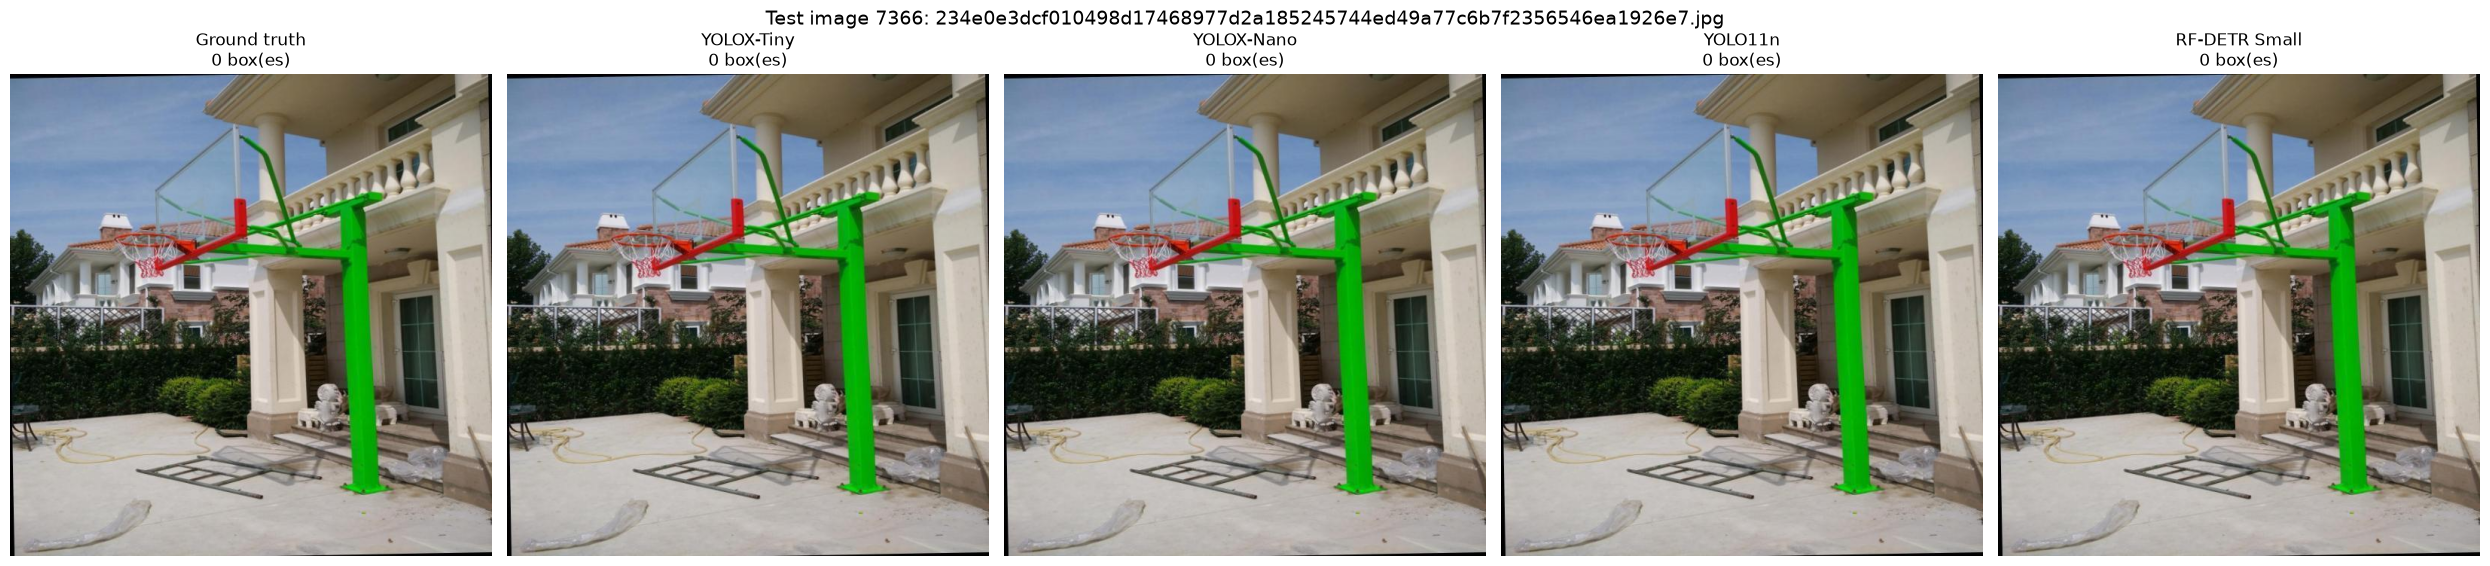

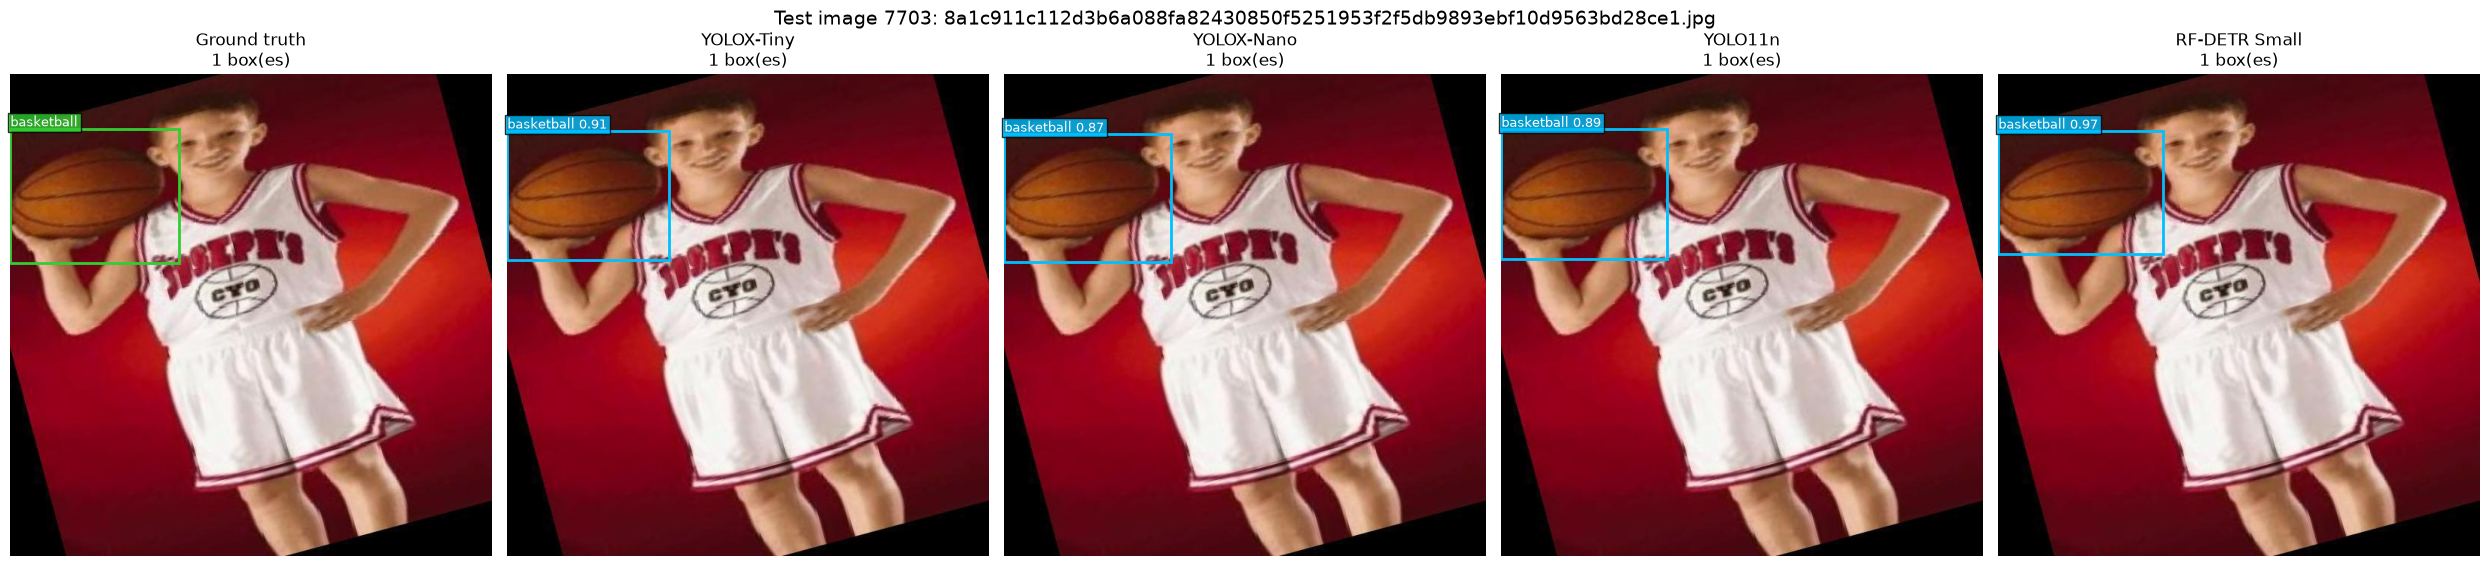

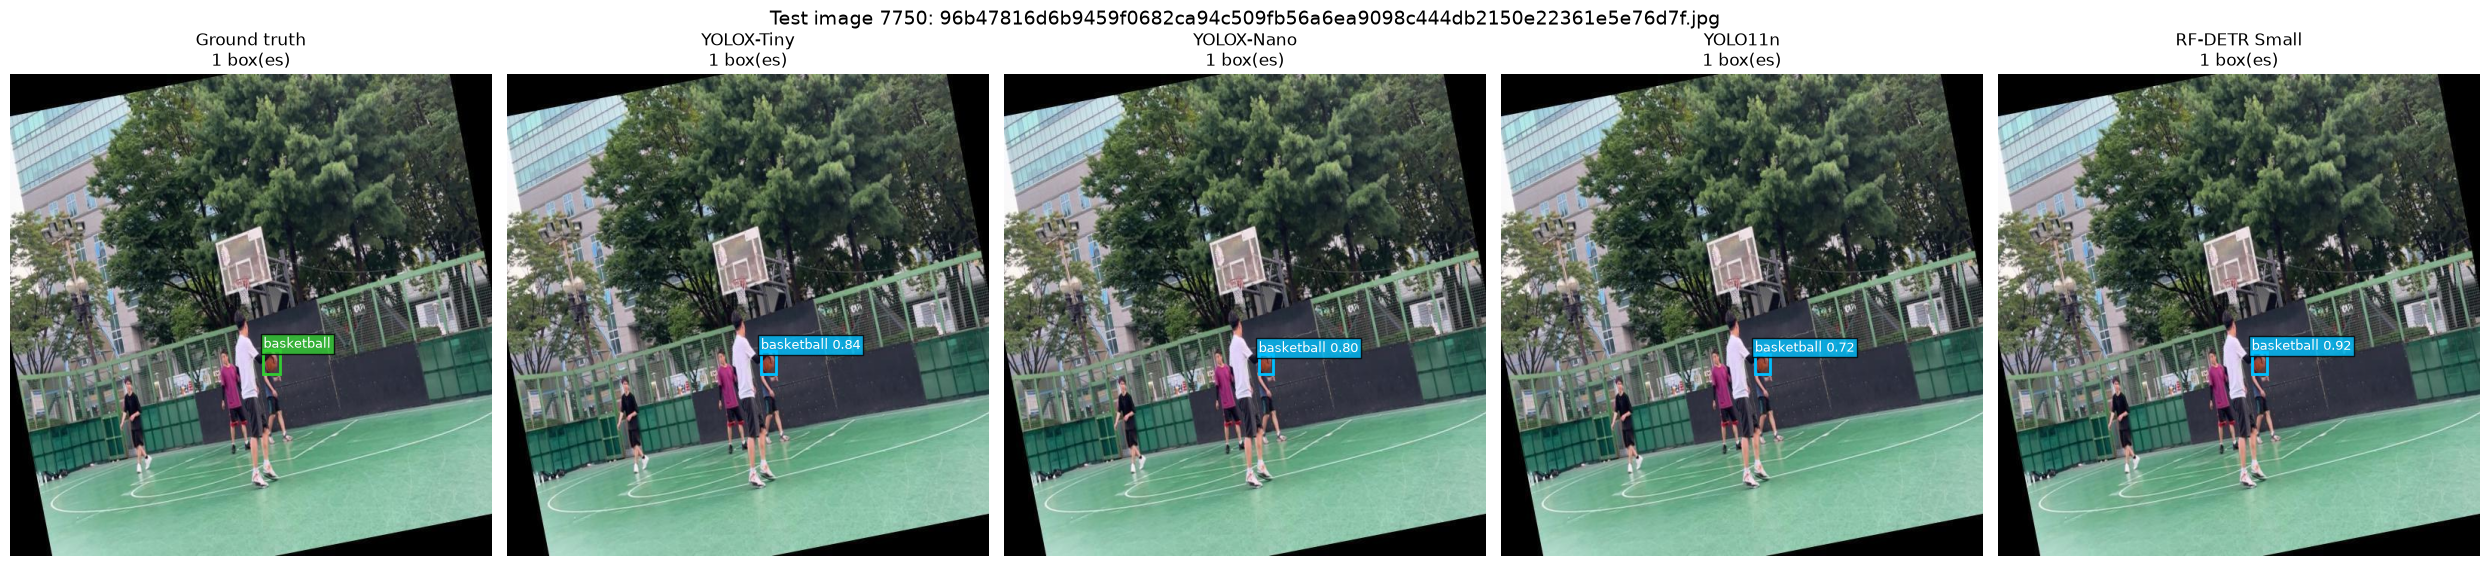

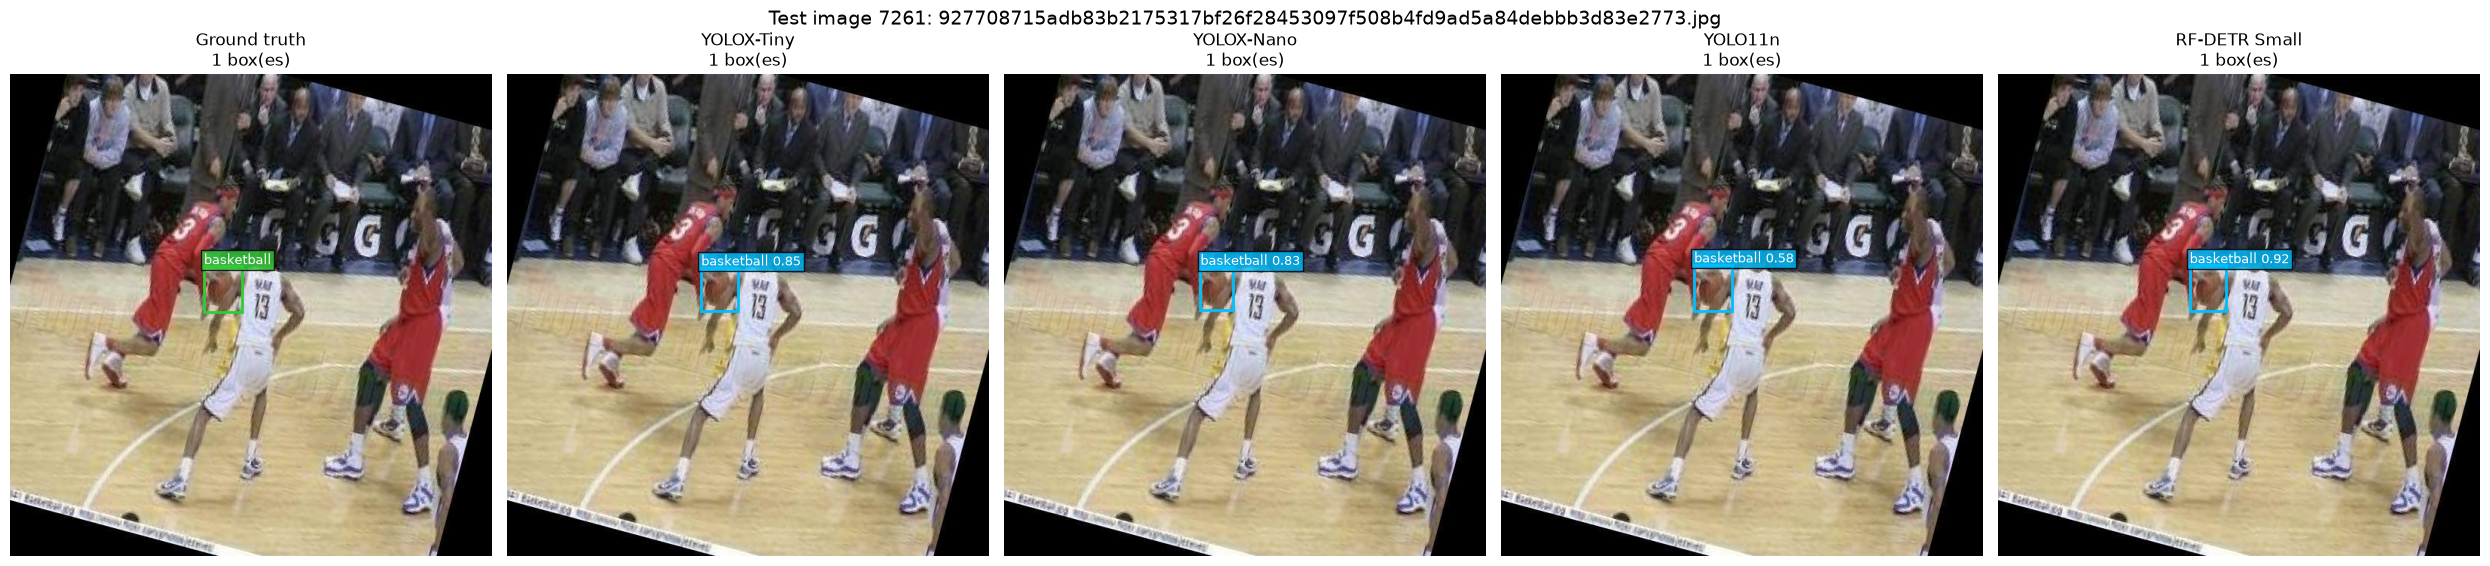

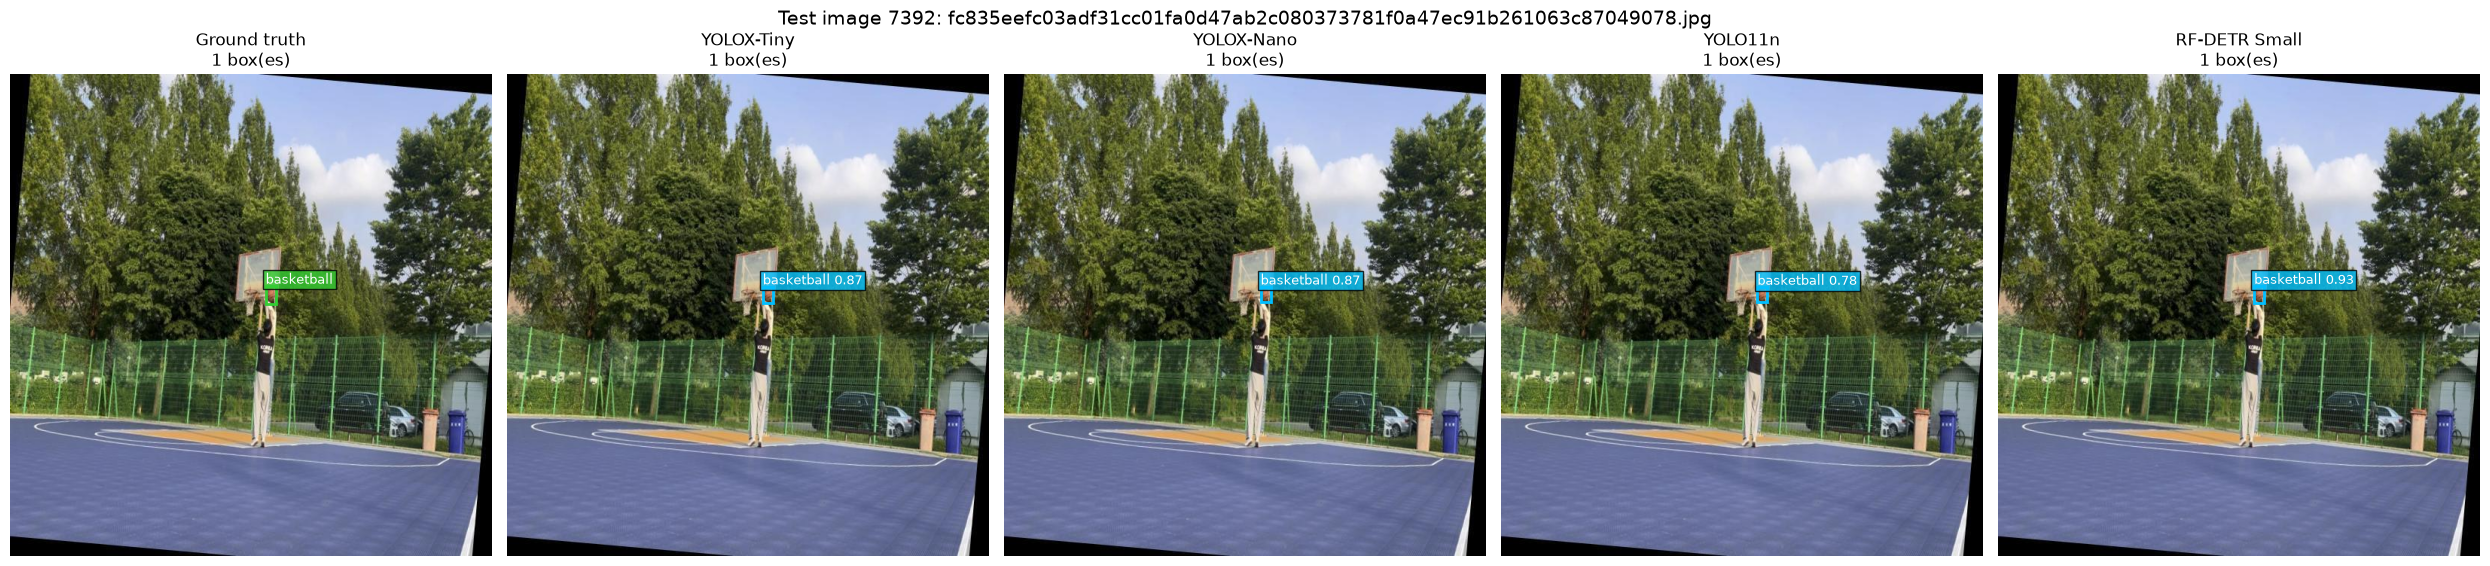

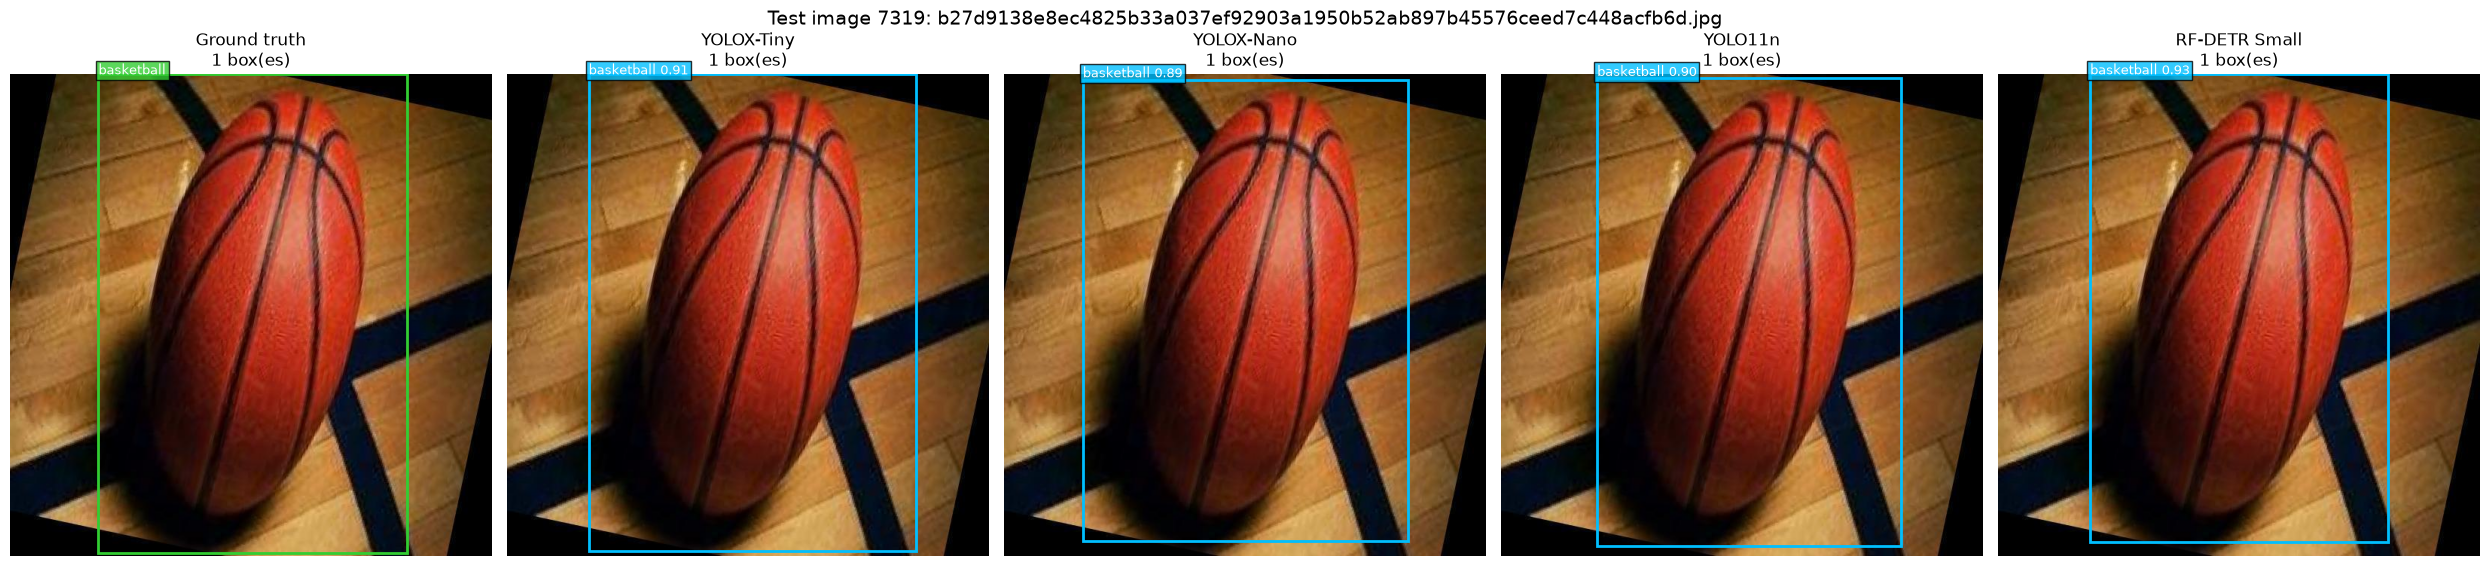

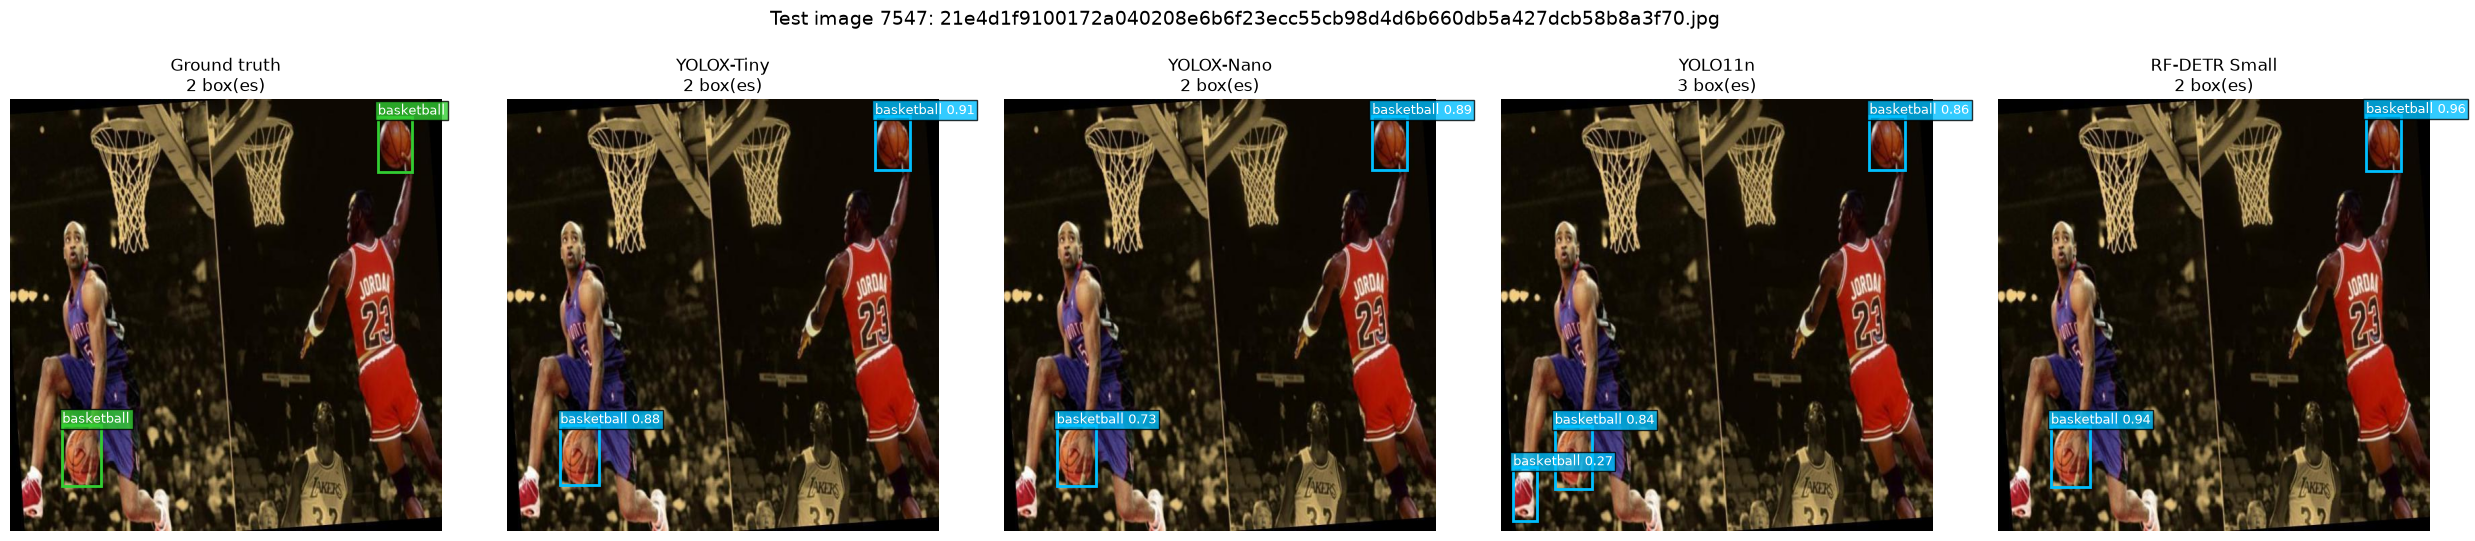

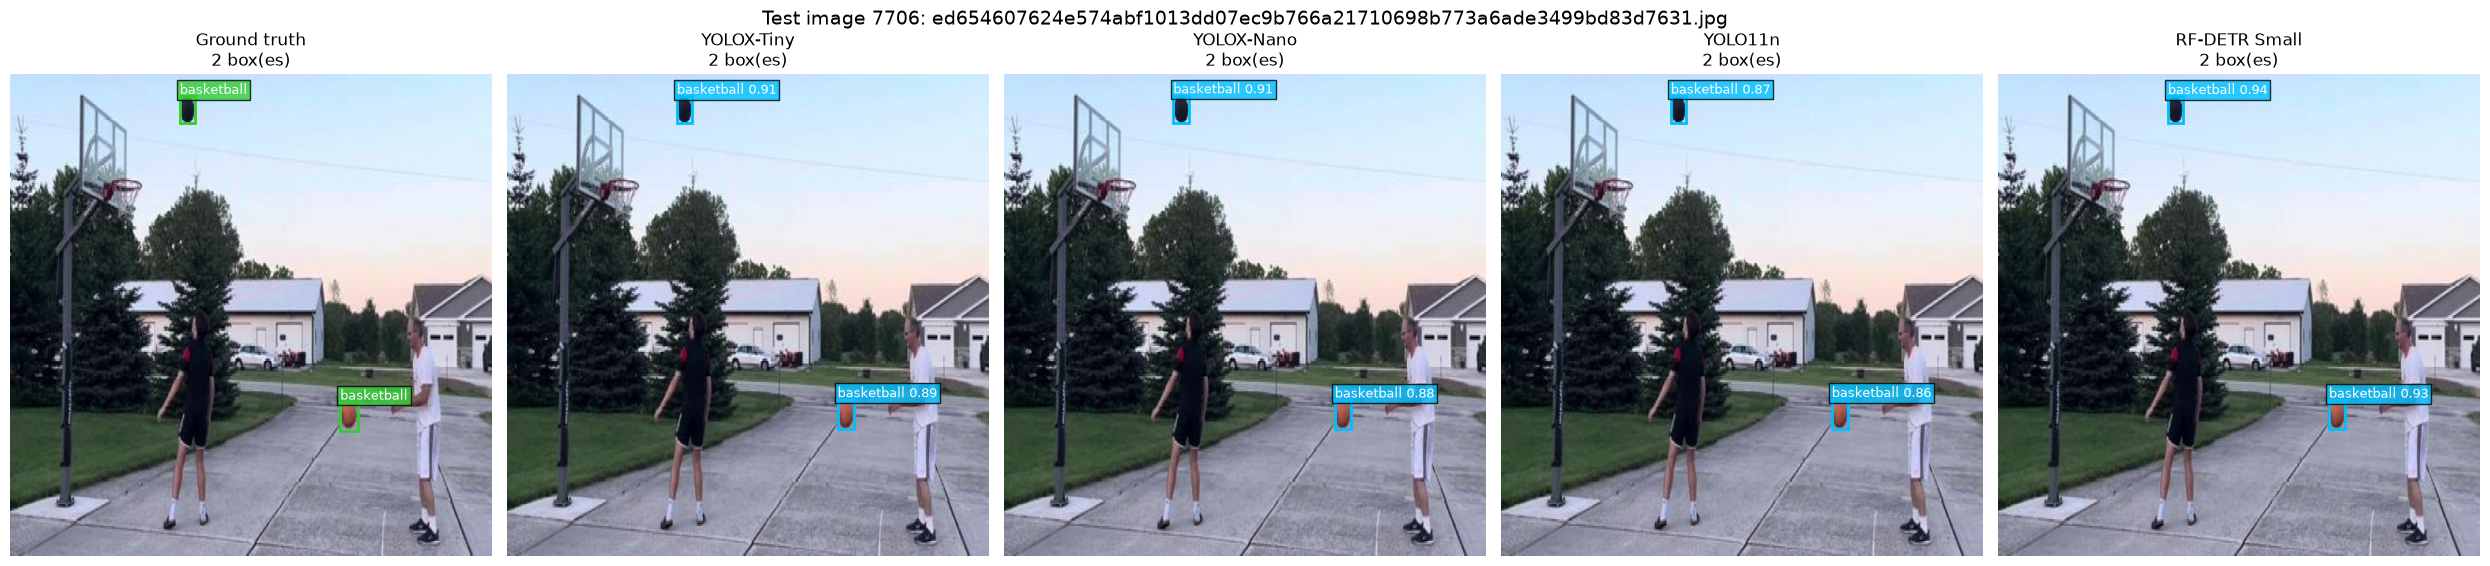

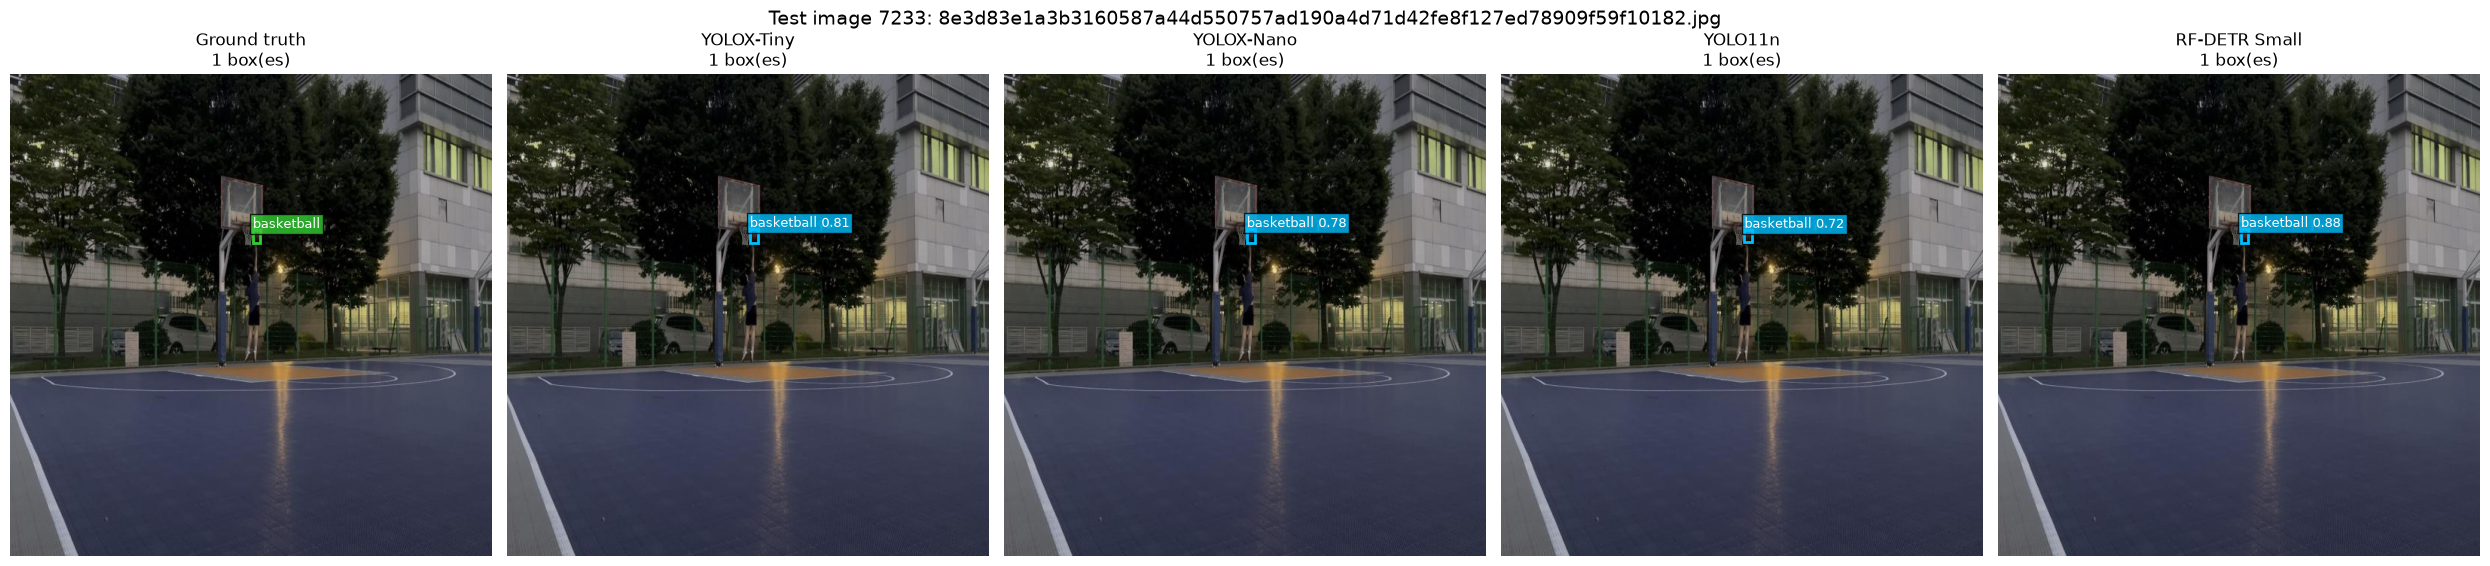

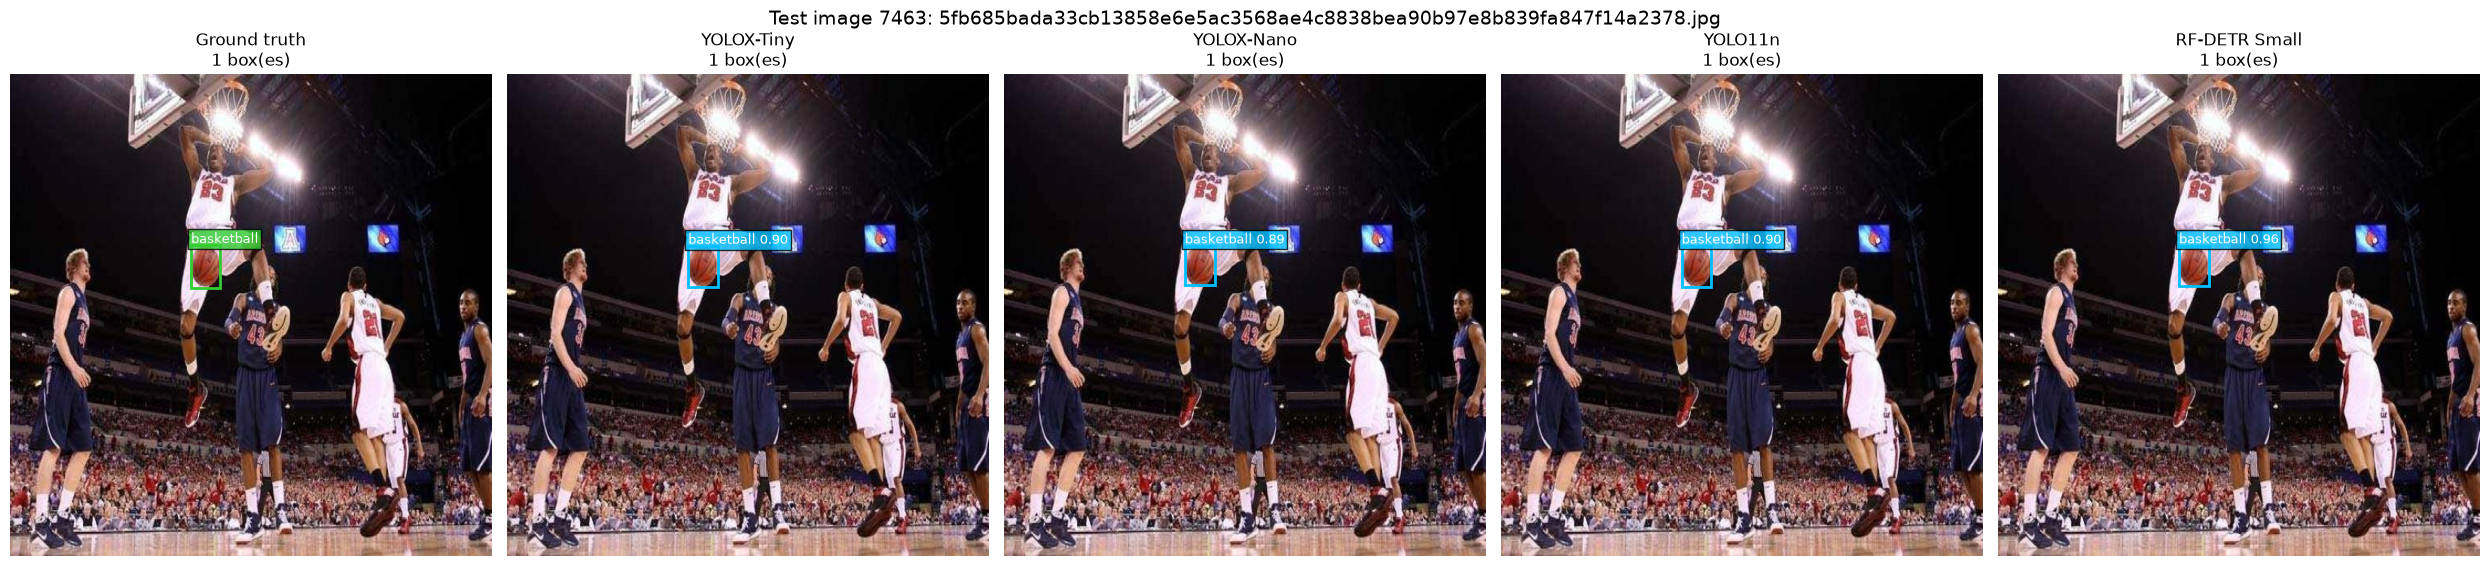

In [8]:
def draw_panel(
    axis: Axes,
    image: Image.Image,
    boxes: list[tuple[int, tuple[float, float, float, float], float | None]],
    *,
    title: str,
    color: str,
) -> None:
    """
    Draw labeled COCO xywh boxes over one source-image panel.
    """
    axis.imshow(image)
    for category_id, (x, y, width, height), score in boxes:
        axis.add_patch(
            Rectangle(
                (x, y),
                width,
                height,
                fill=False,
                edgecolor=color,
                linewidth=2,
            )
        )
        label = category_names[category_id]
        if score is not None:
            label = f"{label} {score:.2f}"
        axis.text(
            x,
            max(0, y - 3),
            label,
            color="white",
            fontsize=9,
            bbox={"facecolor": color, "alpha": 0.8, "pad": 2},
        )
    axis.set_title(f"{title}\n{len(boxes)} box(es)")
    axis.axis("off")


for test_image in test_images[:10]:
    figure, axes = plt.subplots(1, 5, figsize=(25, 6), squeeze=False)
    ground_truth_boxes = [
        (
            int(annotation["category_id"]),
            tuple(float(value) for value in annotation["bbox"]),
            None,
        )
        for annotation in test_image["annotations"]
    ]
    draw_panel(
        axes[0, 0],
        test_image["image"],
        ground_truth_boxes,
        title="Ground truth",
        color="limegreen",
    )
    for column, spec in enumerate(model_specs, start=1):
        prediction_boxes = [
            (detection.category_id, detection.bbox, detection.score)
            for detection in cpu_predictions[spec.name][test_image["image_id"]]
        ]
        draw_panel(
            axes[0, column],
            test_image["image"],
            prediction_boxes,
            title=MODEL_DISPLAY_NAMES[spec.name],
            color="deepskyblue",
        )
    figure.suptitle(
        f"Test image {test_image['image_id']}: {test_image['file_name']}",
        fontsize=14,
    )
    figure.tight_layout()
    display(figure)
    plt.close(figure)

## 7. Read the provider comparison

Each row summarizes one model/provider pair across the selected images.
Predictions use `CONFIDENCE_THRESHOLD` (default **0.25**); ground-truth matching
uses `MATCH_IOU_THRESHOLD` (default **0.50** intersection over union, or IoU).

### What the columns mean

| Column | How to read it |
| --- | --- |
| `predictions` | Total predicted boxes across successful images. |
| `precision` | Share of predicted boxes that match ground truth. |
| `recall` | Share of ground-truth boxes that were detected. |
| `F1` | Harmonic mean of precision and recall. |
| `latency (ms)` | Mean of the per-image median inference times. |
| `images/s` | `1000 / latency (ms)`, using the mean latency above. |
| `error` | Reason a provider case was unavailable or incomplete. |

Precision, recall, and F1 are calculated **per image, then averaged** across
successful images. They are diagnostics for this selection; use the
[full-split model comparison](nb05.01-basketball_models_comparison.ipynb) for
dataset-level average precision (AP) and average recall (AR).

### What the latency includes

Timing measures one image at a time (**batch size 1, FP32**), including
in-memory preprocessing, ONNX inference, and postprocessing. It excludes
file I/O, model loading, CoreML compilation, and drawing.

> **Check `error` before comparing providers.** Summaries include successful
> images only, so incomplete cases may cover fewer images. CoreML-first
> timings can include CPU fallback. Compare rows measured on the same host
> with the same settings.

In [9]:
comparison = pd.DataFrame(
    comparison_rows,
    columns=[
        "model",
        "provider",
        "predictions",
        "precision",
        "recall",
        "f1",
        "latency_ms",
        "error",
    ],
).groupby(["model", "provider"], as_index=False, sort=False).agg(
    predictions=("predictions", lambda values: values.sum(min_count=1)),
    precision=("precision", "mean"),
    recall=("recall", "mean"),
    f1=("f1", "mean"),
    latency_ms=("latency_ms", "mean"),
    error=("error", lambda values: "; ".join(dict.fromkeys(values.dropna())) or None),
)
comparison.insert(
    comparison.columns.get_loc("error"),
    "images_per_second",
    1000.0 / comparison["latency_ms"],
)
comparison = comparison.round(3)
display(
    comparison.rename(
        columns={
            "f1": "F1",
            "latency_ms": "latency (ms)",
            "images_per_second": "images/s",
        }
    )
)

if comparison["error"].notna().any():
    display(
        Markdown(
            "**CoreML note:** one or more CoreML-first cases were unavailable. "
            "The CPU-reference comparison is complete; inspect the `error` column "
            "before treating CoreML performance as complete."
        )
    )

,model,provider,predictions,precision,recall,F1,latency (ms),images/s,error
0,yolox_tiny,cpu_reference,99,0.800,0.815,0.803,74.082,13.499,None
1,yolox_tiny,coreml_first,99,0.800,0.815,0.803,12.769,78.317,None
2,yolox_nano,cpu_reference,93,0.800,0.800,0.797,31.324,31.924,None
3,yolox_nano,coreml_first,93,0.800,0.800,0.797,9.303,107.487,None
4,yolo11n,cpu_reference,98,0.777,0.790,0.778,41.145,24.304,None
5,yolo11n,coreml_first,98,0.777,0.790,0.778,10.113,98.883,None
6,rfdetr_small,cpu_reference,95,0.820,0.815,0.813,399.111,2.506,None
7,rfdetr_small,coreml_first,95,0.820,0.815,0.813,94.477,10.585,None
